In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import glob

OUTPUT_DIR = Path("./eval_detection_subject06")

In [3]:
summary_csv = OUTPUT_DIR / "summary_per_activity.csv"
global_ap_csv = OUTPUT_DIR / "global_ap_by_iou.csv"
global_txt = OUTPUT_DIR / "global_results.txt"

activity_ap_files = sorted(
    [
        str(p) for p in OUTPUT_DIR.glob("*_ap_by_iou.csv")
        if p.name != "global_ap_by_iou.csv"
    ]
)

print("Fichiers trouvés :")
print(f"- summary_per_activity.csv : {summary_csv.exists()}")
print(f"- global_ap_by_iou.csv     : {global_ap_csv.exists()}")
print(f"- global_results.txt       : {global_txt.exists()}")
print(f"- nb fichiers activité AP  : {len(activity_ap_files)}")

Fichiers trouvés :
- summary_per_activity.csv : True
- global_ap_by_iou.csv     : True
- global_results.txt       : True
- nb fichiers activité AP  : 8


In [4]:
if global_txt.exists():
    with open(global_txt, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("global_results.txt introuvable")

EVALUATION DETECTION
GT_ROOT: GT_detect_metasport06
VIDEOS_ROOT: \\intram\Paris\Labo\IBHGC\PROJETS\metasport\DATA\METASPORT06_undistort\Session1\Files\fichiers_video\Bruts
PRED_ROOT: results_1\videos_eval_s6\ResultsMETASPORT06Rtmlib_V3
SCORE_THRESHOLD: None
OPERATING_IOU: 0.5

n_images: 4260
n_gt: 8501
n_pred: 8565
TP: 8188
FP: 377
FN: 313
Precision: 0.955984
Recall: 0.963181
F1: 0.959569
Mean IoU: 0.899202
AP50: 0.958531
mAP50-95: 0.773545



In [5]:
if summary_csv.exists():
    summary = pd.read_csv(summary_csv)
    display(summary)
else:
    raise FileNotFoundError(f"Fichier introuvable: {summary_csv}")

,activity,n_images,n_gt,n_pred,tp,fp,fn,precision,recall,f1,mean_iou,ap50,map50_95
0,CMJump_03,488,1407,1428,1329,99,78,0.930672,0.944563,0.937566,0.886455,0.933796,0.726329
1,Deadlift_03,648,1230,1234,1195,39,35,0.968395,0.971545,0.969968,0.895991,0.968616,0.772944
2,Deadlift_Polystyrene_03,592,1120,1106,1094,12,26,0.989150,0.976786,0.982929,0.906645,0.969980,0.804740
3,EpauleDebout_03,932,1769,1765,1699,66,70,0.962606,0.960430,0.961517,0.907103,0.959037,0.791540
4,EpauleDebout_Polystyrene_03,864,1553,1522,1493,29,60,0.980946,0.961365,0.971057,0.904262,0.959806,0.789269
5,SledPush_03,204,343,353,333,20,10,0.943343,0.970845,0.956897,0.895342,0.967371,0.762781
6,SprintTapis_03,124,232,239,222,17,10,0.928870,0.956897,0.942675,0.887870,0.949475,0.750783
7,SquatJump_03,408,847,918,823,95,24,0.896514,0.971665,0.932578,0.893687,0.968006,0.764740


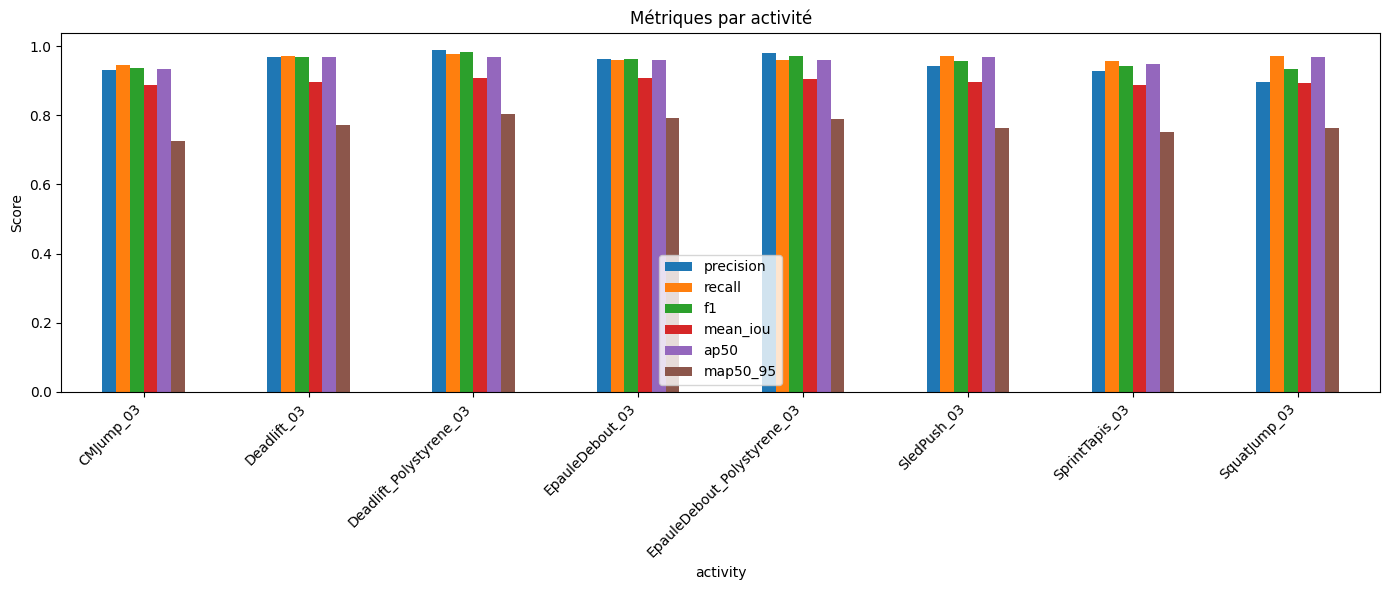

In [6]:
# Métriques principales par activité
cols = ["precision", "recall", "f1", "mean_iou", "ap50", "map50_95"]

ax = summary.set_index("activity")[cols].plot(kind="bar", figsize=(14, 6))
ax.set_title("Métriques par activité")
ax.set_ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

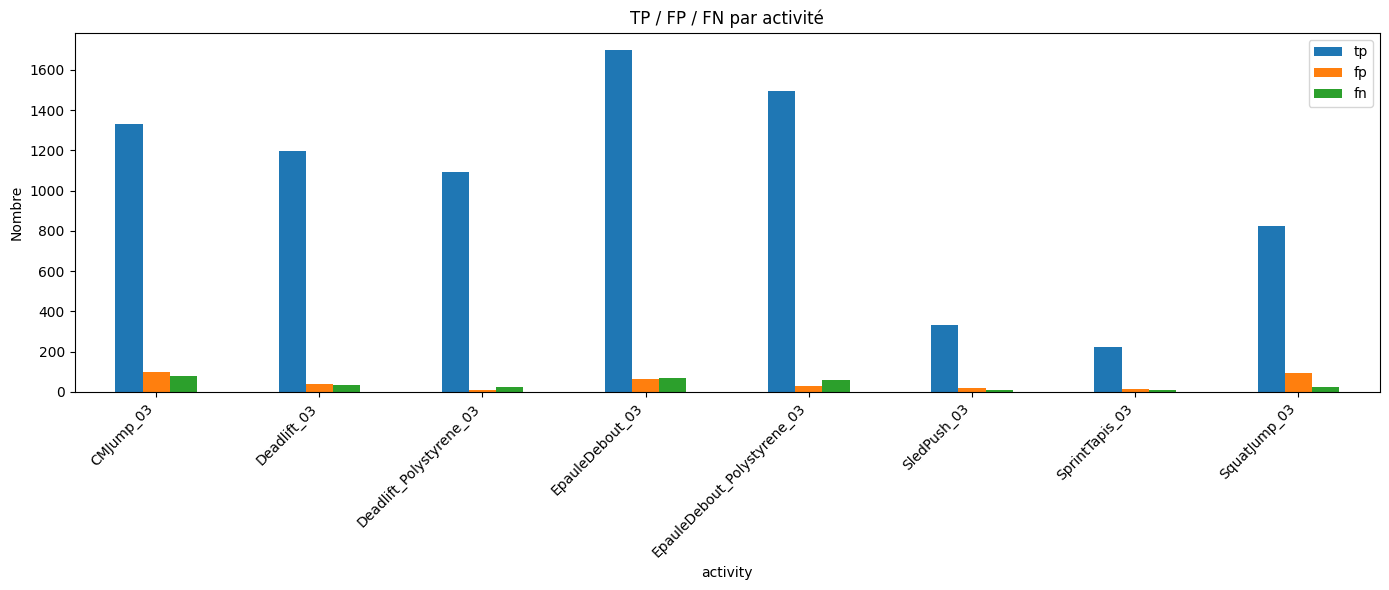

In [7]:
# TP / FP / FN par activité
ax = summary.set_index("activity")[["tp", "fp", "fn"]].plot(kind="bar", figsize=(14, 6))
ax.set_title("TP / FP / FN par activité")
ax.set_ylabel("Nombre")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

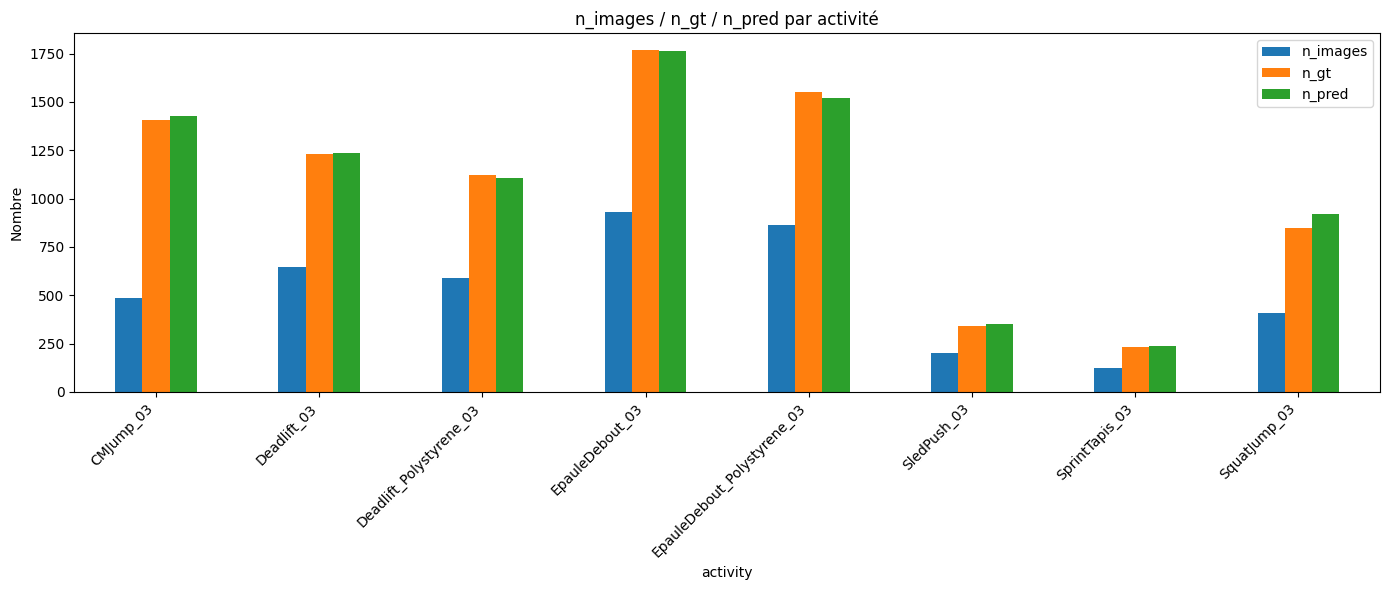

In [8]:
# n_images / n_gt / n_pred par activité
ax = summary.set_index("activity")[["n_images", "n_gt", "n_pred"]].plot(kind="bar", figsize=(14, 6))
ax.set_title("n_images / n_gt / n_pred par activité")
ax.set_ylabel("Nombre")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
if global_ap_csv.exists():
    global_ap = pd.read_csv(global_ap_csv)
    display(global_ap)
else:
    raise FileNotFoundError(f"Fichier introuvable: {global_ap_csv}")

,iou,ap
0,0.50,0.958531
1,0.55,0.948345
2,0.60,0.947285
3,0.65,0.936298
4,0.70,0.924281
5,0.75,0.897638
6,0.80,0.830301
7,0.85,0.699584
8,0.90,0.448778
9,0.95,0.144404


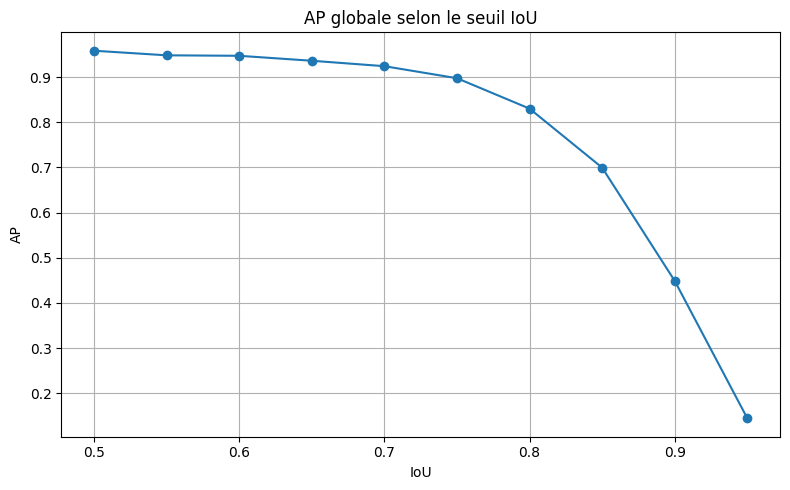

In [10]:
# Courbe AP globale selon le seuil IoU
plt.figure(figsize=(8, 5))
plt.plot(global_ap["iou"], global_ap["ap"], marker="o")
plt.title("AP globale selon le seuil IoU")
plt.xlabel("IoU")
plt.ylabel("AP")
plt.grid(True)
plt.tight_layout()
plt.show()

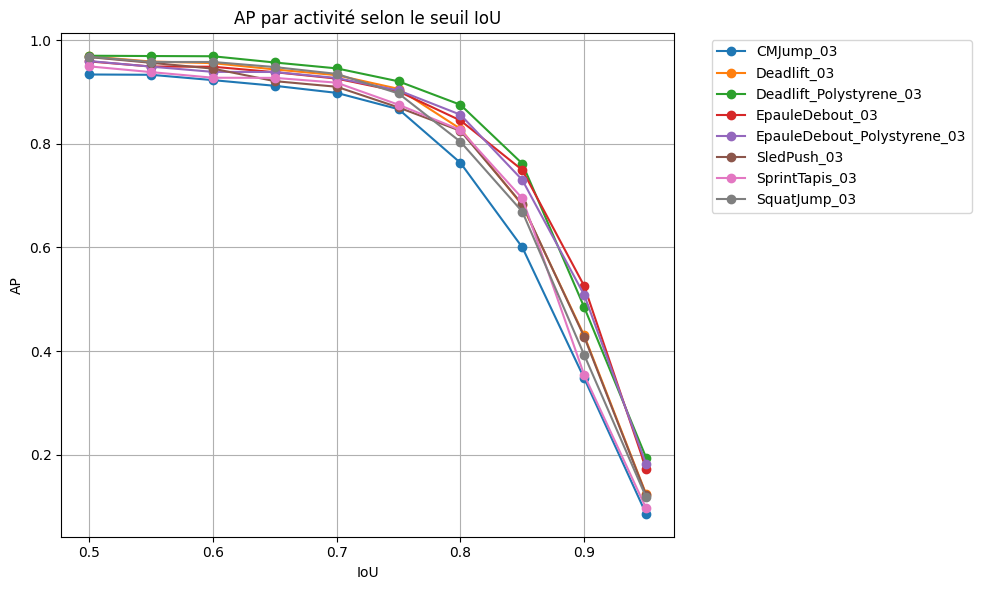

In [11]:
# Courbes AP par activité selon le seuil IoU
plt.figure(figsize=(10, 6))

for ap_file in activity_ap_files:
    ap_df = pd.read_csv(ap_file)
    activity_name = Path(ap_file).name.replace("_ap_by_iou.csv", "")
    plt.plot(ap_df["iou"], ap_df["ap"], marker="o", label=activity_name)

plt.title("AP par activité selon le seuil IoU")
plt.xlabel("IoU")
plt.ylabel("AP")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [12]:
# Affichage détaillé des AP par activité
for ap_file in activity_ap_files:
    activity_name = Path(ap_file).name.replace("_ap_by_iou.csv", "")
    ap_df = pd.read_csv(ap_file)
    print("=" * 60)
    print(activity_name)
    display(ap_df)

CMJump_03


,iou,ap
0,0.50,0.933796
1,0.55,0.933198
2,0.60,0.922895
3,0.65,0.911945
4,0.70,0.898291
5,0.75,0.866811
6,0.80,0.763248
7,0.85,0.600071
8,0.90,0.347309
9,0.95,0.085725


Deadlift_03


,iou,ap
0,0.50,0.968616
1,0.55,0.958848
2,0.60,0.955673
3,0.65,0.943542
4,0.70,0.932468
5,0.75,0.906001
6,0.80,0.828882
7,0.85,0.681483
8,0.90,0.429944
9,0.95,0.123983


Deadlift_Polystyrene_03


,iou,ap
0,0.50,0.969980
1,0.55,0.969407
2,0.60,0.968983
3,0.65,0.956930
4,0.70,0.945590
5,0.75,0.920549
6,0.80,0.875360
7,0.85,0.761720
8,0.90,0.484520
9,0.95,0.194356


... (6 outputs left out)

SprintTapis_03


,iou,ap
0,0.50,0.949475
1,0.55,0.938403
2,0.60,0.927534
3,0.65,0.927248
4,0.70,0.917981
5,0.75,0.875424
6,0.80,0.826627
7,0.85,0.694675
8,0.90,0.353765
9,0.95,0.096702


SquatJump_03


,iou,ap
0,0.50,0.968006
1,0.55,0.957925
2,0.60,0.957906
3,0.65,0.948098
4,0.70,0.934914
5,0.75,0.897131
6,0.80,0.804019
7,0.85,0.669003
8,0.90,0.392387
9,0.95,0.118011
